# <center> Clase 07: Introducción al aprendizaje por refuerzo </center>


**Agenda:**

    7.1.- Introducción al aprendizaje por refuerzo
      7.1.1.- Procesos de decisión
      7.1.2.- Programación dinámica
      7.1.3.- Bandido multibrazo
      7.1.4.- Método de Montecarlo
      7.1.5.- Diferencias temporales
      7.1.6.- Policy iteration vs Value iteration
      7.1.7.- On-policy vs Off-policy

    7.2.- Model-free RL
      7.2.1.- Q-learning
      7.2.2.- Policy gradients

    7.3.- Model-based RL
      7.3.1.- Modelos de horizonte deslizante finito
      7.3.2.- Sistemas de Monte Carlo Híbridos
      
    7.4.- Aplicaciones prácticas
      7.4.1.- Ejemplo de bandido multibrazo
      7.4.2.- Ejemplo de Q-learning
      7.4.3.- Ejemplo de Model Predictive Control


## 7.1.- Introducción al aprendizaje por refuerzo

### 7.1.1.- Procesos de decisión

Un proceso de decisión de Markov (**Markov Decision Process, MDP**) es un proceso de control estocástico de tiempo discreto. Proporciona un marco matemático para modelar la toma de decisiones en situaciones donde los resultados son en parte aleatorios y en parte bajo el control de un tomador de decisiones. Se utilizan en muchas disciplinas, incluida la robótica, el control automático, la economía y la fabricación.

En aprendizaje por refuerzo, existe un, en primer lugar, **entorno** que genera nuevos estados y recompensas en cada paso y, en segundo lugar, un **agente** que recibe **recompensas** del entono en función al estado de éste y a la acción del agente, lo que ayuda a que el agente aprenda qué acción debería hacer para cada circunstancia del entorno para maximizar las recompensas futuras. 

El aprendizaje por refuerzo difiere del estándar de aprendizaje supervisado en el que los pares de entradas / salidas correctas nunca se presentan, ni acciones subóptimas corregidas explícitamente. El aprendizaje por refuerzo (reinforcement learning) consiste en aprender a escoger la secuencia de acciones que debe escoger un agente para **maximizar las recompensas futuras**, siendo, en cierto modo, un problema de programación dinámica aproximada o de control óptimo, aunque la mayoría de los estudios se centran en la existencia de soluciones óptimas y su caracterización, no en los aspectos de aprendizaje o de aproximación.

### 7.1.2.- Programación dinámica

La programación dinámica es una técnica desarrollada por el matemático Richard Bellman en la década de 1950. Sirve para resolver algunos problemas de optimización complejos, descomponiéndolos en subproblemas más sencillos. Este método se basa en el **principio de optimalidad de Bellman** según el cual “dada una secuencia óptima de decisiones, toda subsecuencia de ella es, a su vez, óptima”. Se trata de una herramienta muy conocida en el campo de la informática, aunque su utilidad se extiende a otras muchas áreas.

### 7.1.3.- Bandido multibrazo

El problema del bandido multi-brazo proviene de imaginar a un jugador en una fila de máquinas tragaperras, que se debe decidir en qué máquinas jugar, cuántas veces jugar en cada máquina y en qué orden jugarlas, y si continuar con la máquina actual o probar una máquina diferente. En el problema, cada máquina proporciona una recompensa aleatoria a partir de una distribución de probabilidad específica de esa máquina, que no se conoce a priori. El objetivo del jugador es maximizar la suma de las recompensas obtenidas a través de una secuencia de tirones de palanca. La compensación crucial que enfrenta el jugador en cada prueba es entre la "**explotación**" de la máquina que tiene el pago esperado más alto y la "**exploración**" para obtener más información sobre los pagos esperados de las otras máquinas.

Entre los algoritmos de resolución más comunes habría que destacar los siguientes:
* **Epsilon greedy**: se decide si se juega con el mejor bandido o si se hace de forma completamente aleatoria. El porcentaje de veces en las que la estrategia jugará de forma aleatoria se seleccionará mediante un valor epsilon que va decreciendo con el tiempo. Así se obtendrá la mejor recompensa con la información disponible, al mismo tiempo que es posible explorar otras soluciones con las tiradas aleatorias.
* **UCB (Upper Confidence Bounds)**: algoritmo determinista para el aprendizaje por refuerzo que se centra en la exploración y explotación en función de un límite de confianza que el algoritmo asigna a cada máquina en cada ronda de exploración. Estos límites disminuyen cuando una máquina se usa más en comparación con otras máquinas.
* **Regla de Thompson**: adopta un enfoque bayesiano: en lugar de simplemente refinar una estimación de la recompensa media, la amplía para construir un modelo de probabilidad a partir de las recompensas obtenidas y luego toma muestras de esto para elegir una acción.
* **ALP-GMM**: es un algoritmo que aprende a generar un plan de estudios de aprendizaje (curriculum learning) para agentes de aprendizaje de refuerzo de caja negra, mediante el cual muestrea secuencialmente parámetros que controlan una generación de procedimientos estocásticos de tareas o entornos.

### 7.1.4.- Método de Montecarlo

Los Método de Montecarlo consisten en generar secuencias de acciones aleatorias con el fin de ir descubriendo el entorno para, al final de cada secuencia, evaluar los resultados e ir actualizando la forma de proceder del agente. En la etapa de mejora de las políticas, como se hace en el algoritmo de iteración, la siguiente política se obtiene mediante el cálculo de una política greedy: Dado un estado, la nueva política devuelve una acción que **maximiza el sumatorio de recompensas futuras**. En la práctica se utiliza evaluación perezosa (lazy) para aplazar el cómputo de las acciones que maximizan cuando realmente sea necesario, lo que puede acarrear algunos problemas como los siguientes:
- Se puede perder mucho tiempo en la evaluación de una política subóptima;
- Utilizar muestras de manera ineficiente
- Cuando las trayectorias tienen una alta varianza, la convergencia será lenta;
- Funciona solo en los problemas episódicos;
- Actúa en solo MDPs pequeños y finitos.

### 7.1.5.- Diferencias temporales

Se trata de permitir que el procedimiento pueda cambiar la policy **antes de que los valores se establezcan**, lo cual resuelve los problemas de lenta convergencia en el Método de Montecarlo, pero podría no explorar lo suficiente. El cálculo en métodos TD puede ser incrementales (cuando después de cada transición de la memoria se cambia y la transición se desecha), o por lotes (cuando se recogen las transiciones y luego las estimaciones se calculan una vez sobre la base de un gran número de transiciones). El métodos por lotes, un excelente ejemplo de lo que es el método de mínimos cuadrados diferencia temporal, puede utilizar la información de las muestras mejor, mientras que los métodos incrementales son la única opción cuando los métodos de proceso por lotes se convierten en inviable debido a su alta computacional o la complejidad de la memoria.

### 7.1.6.- Policy iteration vs Value iteration


- <ins>Policy iteration</ins>: comenzamos eligiendo una política arbitraria. Luego, evaluamos y mejoramos iterativamente la política hasta la convergencia. Luego, calculamos la política mejorada utilizando la anticipación de un paso para reemplazar la política inicial. Al principio, no nos importa si la política inicial es óptima o no. Durante la ejecución, nos concentramos en mejorarlo en cada iteración repitiendo los pasos de evaluación y mejora de políticas. Usando este algoritmo producimos una cadena de políticas, donde cada política es una mejora sobre la anterior

- <ins>Value iteration</ins>: calculamos la función de valor de estado óptimo actualizando iterativamente la estimación política vs valor iteración valor 1. Empezamos con una función de valor aleatorio V(s). En cada paso, lo actualizamos:

### 7.1.7.- On-policy vs Off-policy

Los algoritmos Off-Policy hacen que la actualización de las policy sean independiente de la propia policy que está llevando a cabo el agente, mientras que los métodos on-policy lo hace sobre la propia policy que se utilizando en ese momento para tomar decisiones. Cada alternativa presenta sus ventajas e inconvenientes, que se podrían resumir del siguiente modo:
* Las técnicas <ins>off-policy</ins> dan más flexibilidad a la hora de realizar cambios sobre otras policies o sobre la propia policy de forma diferida, lo que en técnicas como el Q-learning, de este tipo, permite realizar evaluaciones y actualizaciones en batch. Por contra, a veces converge hacia policies poco robustas ante perturbaciones, como acercar excesivamente al agente al borde de un precipicio. Es decir, las técnicas off-policy se destacan por disponer de **experience replay**, que es el acto de almacenar y reproducir estados del juego (el estado, la acción, la recompensa, el siguiente_estado) de los que el algoritmo RL puede aprender. Se puede usar en algoritmos fuera de política para aprender sin conexión.
* Las técnicas <ins>on-policy</ins> resultan más naturales e intuitivas tanto para desarrollar como para monitorizar, pero computacionalmente pueden ser sub-óptimas en muchas ocasiones al no poder realizar actualizaciones por lotes como en el caso de las off-policy. Otra ventaja de esto es que tenderán a escoger secuencias de acciones más robustas ante perturbaciones, lo que las hace más adecuadas ante dificultades en el control del agente. Un ejemplo de estas técnicas es el método SARSA (State–action–reward–state–action).

## 7.2.- Model-free RL

### 7.2.1.- Q-learning

El Q-learning es un algoritmo de aprendizaje por refuerzo en el que, en cada estado y para cada acción, se van estimando una serie de valores Q que representan las **expectativas de ganancias futuras** del agente en caso de que decida llevar a cabo cada una de dichas acciones. De este modo, en fase de aprendizaje el agente va escogiendo la acción con el valor Q más alto (para sacar partido a lo aprendido en modo "exploit") o cualquier otra acción aleatoria con el fin de aprender ("explore"), lo que hace que paulatinamente, según se reduce la tasa de "explore" mediante programas de **epsilon-greedy**, el agente acaba tomando decisiones óptimas o cercanas al óptimo.

El algoritmo Q-learning utiliza el método de diferencias temporales y actualiza los valores de Q de forma iterativa inspirándose en el **criterio de Bellman** utilizado en optimización dinámica tal y como vemos en la fórmula de abajo. Para ello existe una tasa de aprendizaje alfa y un factor de descuento gamma, que representa la importancia que el agente da a beneficios futuros ante los beneficios presentes.

### 7.2.2.- Policy Gradient

Se trata de una técnica de aprendizaje por refuerzo basada en el **teorema Policy Gradient**, que dice que "la derivada de la recompensa esperada es la expectativa del producto de la recompensa y el gradiente del logaritmo de la política".

Para comprender este cálculo, analicemos: P representa la distribución ergódica de comenzar en algún estado. A partir de ahí, aplicamos la regla del producto de probabilidad porque cada nueva probabilidad de acción es independiente de la anterior. En cada paso, tomamos alguna acción usando la policy y la dinámica del entorno p decide a qué nuevo estado hacer la transición. Esos se multiplican por T pasos de tiempo que representan la longitud de la trayectoria. Este resultado nos dice que realmente **no necesitamos saber sobre la distribución de los estados ni la dinámica del entorno**. Esto es crucial porque para la mayoría de los propósitos prácticos, es difícil modelar ambas variables, lo cual podemos evitar en est tipo de algortmos model-free.

Los dos algoritmos más conocidos de este tipo son:
* **REINFORCE**: es una variante estocástica del método policy gradients en la que el agente recopila una trayectoria de un episodio usando su política actual y la usa para actualizar el parámetro de la política. Dado que se debe completar una trayectoria completa para construir un espacio de muestra, REINFORCE se actualiza off-policy.
* **Actor-Critic**: El método Actor-Crítico es una versión de diferencia temporal (TD) de tipo Polcy Gradient. Tiene dos redes: Actor y Crítica. El actor decidía qué acción debía tomarse y el crítico le informaba qué tan buena era la acción y cómo debía ajustarse. El aprendizaje del actor se basa en el enfoque de gradiente de políticas. En comparación, los críticos evalúan la acción producida por el actor calculando la función de valor.

## 7.3.- Model-based RL

### 7.3.1.- Modelos de horizonte deslizante finito

Este tipo de métodos, también llamados **Model Predictive Control (MPC)**, un método avanzado de control de procesos que consiste en utilizar sistemas predictivos para evitar que el agente deba equivocarse continuamente para aprender. De este modo, el agente trata de aprender la evolución del entorno para un cierto horizonte temporal futuro ante sus posibles acciones al mismo tiempo que utiliza algoritmos de optimización para decidir qué acción llevar a cabo. Se trata de una técnica muy adecuada cuando el coste del error en entrenamiento es alto (por ejemplo, sistemas industriales) y, al mismo tiempo, existe cierta predictibilidad acerca de cómo podría evolucionar el entorno de foma orgánica y ante acciones del agente.

Otro modo de abordar este tipo de técnicas, sobre todo cuando no operan en tiempo real excesivamente rápido, es combinar un modelo de simulación con modelos predictivos y técnicas de optimización. De este modo, para cada instante se estima, para cada posible solución de control, una evolución posible del sistema, se evalúa y se compara entre múltiples soluciones. Mediante un procedimiento iterativo de horizonte deslizante (habitualmente algoritmos metaheurísticos tales como algoritmos genéticos, tabu search, simulated annealing, etc.) se puede establecer un control óptimo pra cada período de tiempo (teniendo en cuenta que, aunque se calcule para todo el horizonte, sólo se opera el que corresponda al siguiente período. 

También es posible controlar el sistema mediante mecanismos de control difuso combinado con redes neuronales que aprendan de modo supervisado tanto los cambios en el entorno como la pólicy óptima.

### 7.3.2.- Sistemas de Monte Carlo híbridos

Otra estrategia muy utilizada, cuyo más éxito reciente fue el sorprendente funcionamiento tanto de AlphaZero como de AlphaGo, fueron los modelos de Monte Carlo basados en la combinación de simulación de Monte Carlo con policies entrenadas mediante técnicas model-free. En concreto, el sistema AlphaGo se basa en la generación de secuencias de jugadas aleatorias mediante la técnica **Monte Carlo Tree Search (MCTS)**, que precisa combinatoria al más puto estilo MPC, y técnicas avanzadas de DRL basados en valoraciones de posición. El enfoque de MCTS se basa en expandir el árbol de búsqueda por medio de un muestreo aleatorio del espacio de búsqueda. La aplicación de la búsqueda del árbol de Monte Carlo en los juegos se basa en muchos playouts, también llamados roll-outs. En cada playout, el juego se desarrolla hasta el final seleccionando movimientos al azar. El resultado final del juego de cada playout se utiliza para ponderar los nodos en el árbol del juego, de modo que es más probable que se elijan mejores nodos en futuros playouts.

La forma más básica de usar los playouts es aplicar el mismo número de playouts después de cada movimiento legal del jugador actual y luego elegir el movimiento que condujo a la mayor cantidad de victorias. La eficiencia de este método, llamado Pure Monte Carlo Game Search, a menudo aumenta con el tiempo a medida que se asignan más playouts a los movimientos que con frecuencia resultaron en la victoria del jugador actual de acuerdo con playouts anteriores. Cada ronda de búsqueda del árbol de Monte Carlo consta de cuatro pasos:
- Selección: comience desde la raíz R y seleccione los nodos secundarios sucesivos hasta alcanzar un nodo hoja L. La raíz es el estado actual del juego y una hoja es cualquier nodo que tiene un hijo potencial desde el cual aún no se ha iniciado ninguna simulación (playout). La siguiente sección ofrece más información sobre una forma de sesgar la elección de los nodos secundarios que permite que el árbol del juego se expanda hacia los movimientos más prometedores, que es la esencia de la búsqueda del árbol de Monte Carlo, pero siendo seleccionados dichos nodos más prometedores por una combinación entre los casos ya explorados y el instinto memorizados por una policy avanzada basada en técnicas model-free.
- Expansión: a menos que L termine el juego de manera decisiva (p. ej., victoria/derrota/empate) para cualquiera de los jugadores, cree uno (o más) nodos secundarios y elija el nodo C de uno de ellos. Los nodos secundarios son cualquier movimiento válido desde la posición del juego definida por L.
- Simulación: complete una reproducción aleatoria desde el nodo C. Este paso a veces también se denomina reproducción o lanzamiento. Un playout puede ser tan simple como elegir movimientos aleatorios uniformes hasta que se decida el juego (por ejemplo, en el ajedrez, el juego se gana, se pierde o se empata).
- Backpropagation: use el resultado de la reproducción para actualizar la información en los nodos en la ruta de C a R.

Este tipo de sistemas de Monte Carlo Híbridos se puede combinar con otras técnicas de asignación de crédito, como por ejemplo mediante la distribucion de feromona y evaporación, tal y como sucede en los algoritmos de colonia de hormigas (**Ant Colony Optimization, ACO**). Estos algoritmos se han utilizado con éxito en la optimización de la climatización (HVAC) y en la optimización de trayectorias en sistemas de tracking multi-cámara.

## 7.4.- Aplicaciones prácticas

### 7.4.1.- Ejemplo de bandido multibrazo

Apliquemos diferentes técnicas de bandido multi-brazo para la óptimización de landing pages en websites.

In [6]:
# from Coursera_Reinforcement_Learning

import matplotlib.pyplot as plt
import numpy as np 
import pandas as pd
from tqdm import tqdm 

In [ ]:
# environment web pages0
class environment:
    def __init__(self, probabilities):
        """
        Arguments:
        probabilities: `list` or `np.array` with the probabilities of success of each action.
        """
        self.probabilities = probabilities
    def step(self, action):
        """
        Environment step returning the reward of each action
        
        Arguments:
        action: `int` 
        """
        return 1.0*(np.random.uniform(0,1) <= self.probabilities[action])

env = environment([0.5, 0.75, 0.25])

In [7]:
# example
n_steps = 100
print("Recompensa promedio:\nacción 0:{}\nacción 1:{}\nacción 2:{}\n".format(
    np.mean([env.step(0) for i in range(n_steps)]),
    np.mean([env.step(1) for i in range(n_steps)]),
    np.mean([env.step(2) for i in range(n_steps)])
))

Recompensa promedio:
acción 0:0.52
acción 1:0.67
acción 2:0.31



In [8]:
# auxiliar function for exploitation

def argmax(q_values):
    """
    Takes in a list of q_values and returns the index
    of the item with the highest value. Breaks ties randomly.
    returns: int - the index of the highest value in q_values
    """
    top = float("-inf")
    ties = []
    
    for i in range(len(q_values)):
        if q_values[i] > top:
            top, ties = q_values[i], [i]
        elif q_values[i] == top:
            ties.append(i)

    ind = np.random.choice(ties)

    return ind

In [9]:
# agent class
class EpsilonGreedyAgent():
    def __init__(self, action_size = 3, epsilon = 0.15):
        """
        This class implements an epsilon-greedy agent that takes with probability epsilon a random action
        and with probability 1-p the action with the highest q-value
        
        Arguments:
        epsilon: `float` with the exploration probability
        action_size: `int` cardinality of the action space
        
        Attributes:
        last_action: `int` with the last action taken by the agent
        arm_count: `numpy.array` with the number of times each action has been taken
        q_values: `numpy.array` with the value estimates of taking each action 
        
        """
        # epsilon: probabilidad de exploración del agente
        self.epsilon = epsilon
        # last_action: accion tomada en el paso previo
        self.last_action = None
        # arm_count: número de veces que cada acción se ha tomado
        self.arm_count = np.zeros(action_size)
        # q_values: array con el valor estimado q por el agente para cada opción
        self.q_values = np.zeros(action_size)
        
    def agent_init(self):
        """
        Initialization of the agent to take the first action randomly
        """
        current_action = np.random.randint(len(self.q_values))
        self.last_action = current_action 
        return current_action
        
    def agent_step(self, reward):
        """
        Takes one step for the agent. It takes in a reward and observation and 
        returns the action the agent chooses at that time step.
        
        Arguments:
        reward: `float`, the reward the agent received from the environment after taking the last action.
        Returns:
        current_action : `int`, the action chosen by the agent at the current time step.
        """
        self.arm_count[self.last_action] += 1
        self.q_values[self.last_action] += (reward - self.q_values[self.last_action]) / self.arm_count[self.last_action]

        if np.random.random() < self.epsilon: # exploration
            current_action = np.random.randint(len(self.q_values))
        else:  # explotation
            current_action = argmax(self.q_values)
        
        self.last_action = current_action
        
        return current_action
    

100%|██████████████████████████████████████████████████████████████████████████████████| 10/10 [00:00<00:00, 48.06it/s]


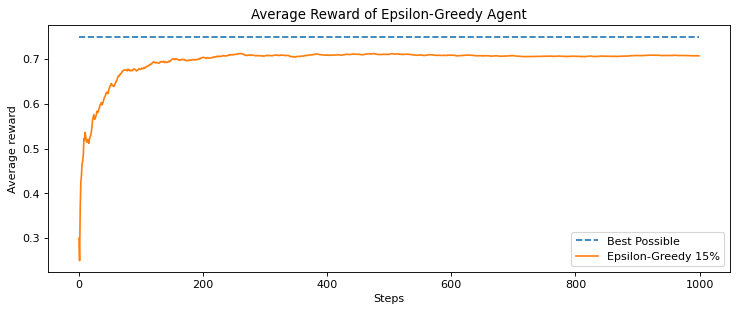

In [10]:
# training

num_runs = 10 #200                      # Número de veces que repetimos el experimento
num_steps = 1000 #100000                  # Número de visitas (pasos) por experimento
probabilities = [0.5, 0.75, 0.25]
epsilon = 0.15
all_averages = []
actions = []
for i in tqdm(range(num_runs)):
    env = environment(probabilities) # Inicializamos el entorno
    agent = EpsilonGreedyAgent(action_size = 3, epsilon = epsilon) # Inicializamos el agente

    action = agent.agent_init()
    actions.append(action)
    scores = [0]
    averages = []
    
    for i in range(num_steps):
        reward = env.step(action)
        action = agent.agent_step(reward)
        actions.append(action)
        scores.append(scores[-1] + reward)
        averages.append(scores[-1] / (i + 1))
    all_averages.append(averages)
      
plt.figure(figsize=(11, 4), dpi= 80, facecolor='w', edgecolor='k')
plt.plot([0.75 for _ in range(num_steps)], linestyle="--")
plt.plot(np.mean(all_averages, axis=0))
plt.legend(["Best Possible", "Epsilon-Greedy 15%"])
plt.title("Average Reward of Epsilon-Greedy Agent")
plt.xlabel("Steps")
plt.ylabel("Average reward")
plt.show()


### 7.4.2.- Ejemplo de Q-learning

Veamos, por ejemplo, como puede aprender un agente a jugar al cuatro en raya por sí sólo mediante el método Q-learning.

In [ ]:
# from https://www.learndatasci.com/tutorials/reinforcement-q-learning-scratch-python-openai-gym/

![Qlearning_model](https://storage.googleapis.com/lds-media/images/Reinforcement_Learning_Taxi_Env.width-1200.png)

In [60]:
import gymnasium as gym
env = gym.make("Taxi-v3").env
env.reset()
env.render()

In [61]:
env.reset() # reset environment to a new, random state
print("Action Space {}".format(env.action_space))
print("State Space {}".format(env.observation_space))

Action Space Discrete(6)
State Space Discrete(500)


0 = south /
1 = north /
2 = east /
3 = west /
4 = pickup /
5 = dropoff /

In [62]:
state = env.encode(3, 1, 2, 0) # (taxi row, taxi column, passenger index, destination index)
print("State:", state)
env.s = state
env.render()

State: 328


In [63]:
env.P[328]

{0: [(1.0, 428, -1, False)],
 1: [(1.0, 228, -1, False)],
 2: [(1.0, 348, -1, False)],
 3: [(1.0, 328, -1, False)],
 4: [(1.0, 328, -10, False)],
 5: [(1.0, 328, -10, False)]}

In [65]:
# examples (not trained yet)

env.s = 328  # set environment to illustration's state
epochs = 0
penalties, reward = 0, 0
frames = [] # for animation
done = False
mex_steps = 10000

while not done:
    action = env.action_space.sample()
    print(epochs,env.step(action))
    state, reward, done2, done, info = env.step(action)

    if reward == -10:
        penalties += 1
    
    # Put each rendered frame into dict for animation
    frames.append({
        #'frame': env.render(mode='ansi'),
        'state': state,
        'action': action,
        'reward': reward
        }
    )
    
    if epochs > mex_steps:
        done = True

    epochs += 1
    
    
print("Timesteps taken: {}".format(epochs))
print("Penalties incurred: {}".format(penalties))

0 (418, -1, False, False, {'prob': 1.0, 'action_mask': array([0, 1, 0, 0, 0, 1], dtype=int8)})
1 (418, -1, False, False, {'prob': 1.0, 'action_mask': array([0, 1, 0, 0, 0, 1], dtype=int8)})
2 (418, -1, False, False, {'prob': 1.0, 'action_mask': array([0, 1, 0, 0, 0, 1], dtype=int8)})
3 (410, 20, True, False, {'prob': 1.0, 'action_mask': array([0, 1, 0, 0, 1, 0], dtype=int8)})
4 (410, -1, False, False, {'prob': 1.0, 'action_mask': array([0, 1, 0, 0, 1, 0], dtype=int8)})
5 (410, -1, False, False, {'prob': 1.0, 'action_mask': array([0, 1, 0, 0, 1, 0], dtype=int8)})
6 (410, -1, False, False, {'prob': 1.0, 'action_mask': array([0, 1, 0, 0, 1, 0], dtype=int8)})
7 (410, -10, False, False, {'prob': 1.0, 'action_mask': array([0, 1, 0, 0, 1, 0], dtype=int8)})
8 (310, -1, False, False, {'prob': 1.0, 'action_mask': array([1, 1, 0, 0, 0, 0], dtype=int8)})
9 (210, -10, False, False, {'prob': 1.0, 'action_mask': array([1, 1, 1, 0, 0, 0], dtype=int8)})
10 (210, -10, False, False, {'prob': 1.0, 'action

4386 (94, -1, False, False, {'prob': 1.0, 'action_mask': array([1, 0, 0, 1, 0, 0], dtype=int8)})
4387 (94, -1, False, False, {'prob': 1.0, 'action_mask': array([1, 0, 0, 1, 0, 0], dtype=int8)})
4388 (94, -10, False, False, {'prob': 1.0, 'action_mask': array([1, 0, 0, 1, 0, 0], dtype=int8)})
4389 (74, -1, False, False, {'prob': 1.0, 'action_mask': array([1, 0, 1, 1, 0, 0], dtype=int8)})
4390 (54, -1, False, False, {'prob': 1.0, 'action_mask': array([1, 0, 1, 0, 0, 0], dtype=int8)})
4391 (54, -1, False, False, {'prob': 1.0, 'action_mask': array([1, 0, 1, 0, 0, 0], dtype=int8)})
4392 (54, -10, False, False, {'prob': 1.0, 'action_mask': array([1, 0, 1, 0, 0, 0], dtype=int8)})
4393 (54, -1, False, False, {'prob': 1.0, 'action_mask': array([1, 0, 1, 0, 0, 0], dtype=int8)})
4394 (54, -10, False, False, {'prob': 1.0, 'action_mask': array([1, 0, 1, 0, 0, 0], dtype=int8)})
4395 (54, -1, False, False, {'prob': 1.0, 'action_mask': array([1, 0, 1, 0, 0, 0], dtype=int8)})
4396 (154, -1, False, False

In [70]:
import numpy as np
q_table = np.zeros([env.observation_space.n, env.action_space.n])

In [80]:
# Training the agent

import random
from IPython.display import clear_output

# Hyperparameters
alpha = 0.1
gamma = 0.6
epsilon = 0.1

# For plotting metrics
all_epochs = []
all_penalties = []
accum_rewards = 0

for i in range(1, 100001):
    state = env.reset()[0]
    epochs, penalties, reward, = 0, 0, 0
    done = False
    ep_rewards = 0
    
    while not done:
        if random.uniform(0, 1) < epsilon:
            action = env.action_space.sample() # Explore action space
        else:
            action = np.argmax(q_table[state]) # Exploit learned values

        next_state, reward, done, done2, info = env.step(action) 
        
        old_value = q_table[state, action]
        next_max = np.max(q_table[next_state])
        
        new_value = (1 - alpha) * old_value + alpha * (reward + gamma * next_max)
        ep_rewards += reward
        q_table[state, action] = new_value

        if reward == -10:
            penalties += 1

        state = next_state
        epochs += 1
        
    if i % 1000 == 0:
        accum_rewards = (accum_rewards + ep_rewards)/2
        #clear_output(wait=True)
        print(f"Episode: {i}: {accum_rewards}")

print("Training finished.\n")

Episode: 1000: -6.5
Episode: 2000: 1.75
Episode: 3000: 2.375
Episode: 4000: -4.8125
Episode: 5000: -5.90625
Episode: 6000: -0.453125
Episode: 7000: 6.2734375
Episode: 8000: 0.63671875
Episode: 9000: 0.318359375
Episode: 10000: 4.1591796875
Episode: 11000: 9.57958984375
Episode: 12000: 10.289794921875
Episode: 13000: 8.1448974609375
Episode: 14000: 9.57244873046875
Episode: 15000: 3.286224365234375
Episode: 16000: 4.6431121826171875
Episode: 17000: 0.8215560913085938
Episode: 18000: -12.589221954345703
Episode: 19000: -9.294610977172852
Episode: 20000: -7.147305488586426
Episode: 21000: 1.926347255706787
Episode: 22000: 5.9631736278533936
Episode: 23000: 8.481586813926697
Episode: 24000: 8.740793406963348
Episode: 25000: 10.870396703481674
Episode: 26000: 8.935198351740837
Episode: 27000: 8.467599175870419
Episode: 28000: 2.7337995879352093
Episode: 29000: 2.8668997939676046
Episode: 30000: -0.06655010301619768
Episode: 31000: -6.533275051508099
Episode: 32000: -1.2666375257540494
Episo